## 📌📌 Breast cancer Survival analysis~~project 1

In [1]:
## loading data.

import pandas as pd
from ipydatagrid import DataGrid

# Load the dataset
data = pd.read_csv(
    r"C:\Users\HP\Downloads\Breast_Cancer.csv"
)

# Display the first 100 rows in an interactive grid

grid = DataGrid(
    data,
    selection_mode="cell",
    editable=False,
    base_column_size=180
)

display(grid)

DataGrid(auto_fit_params={'area': 'all', 'padding': 30, 'numCols': None}, base_column_size=180, corner_rendere…

In [15]:
## Understanding the statistics of the data and checking the follow-up times.

print(data["Survival Months"].describe())
print(data.groupby("Status")["Survival Months"].agg(["count","min","median","max"]))
print(data["Survival Months"].isna().sum())
print(data["Status"].value_counts(dropna=False))

count    4024.000000
mean       71.297962
std        22.921430
min         1.000000
25%        56.000000
50%        73.000000
75%        90.000000
max       107.000000
Name: Survival Months, dtype: float64
        count  min  median  max
Status                         
Alive    3408    1    77.0  107
Dead      616    2    44.0  102
0
Status
Alive    3408
Dead      616
Name: count, dtype: int64


In [2]:
# creating an indicator event for alive and dead person.

data["Event"]=data["Status"].map({
    "Dead":0,
    "Alive":1})

## viewing
from ipydatagrid import DataGrid
Grid=DataGrid(data[["Survival Months","Status","Event"]],
              selection_mode="cell",
              editable=False,
              base_column_size=180)
display(Grid)

DataGrid(auto_fit_params={'area': 'all', 'padding': 30, 'numCols': None}, base_column_size=180, corner_rendere…

In [17]:
#Understanding the columns.

print("\n Column names:")
print(data.columns.tolist())
print(data.shape)


 Column names:
['Age', 'Race', 'Marital Status', 'T Stage ', 'N Stage', '6th Stage', 'differentiate', 'Grade', 'A Stage', 'Tumor Size', 'Estrogen Status', 'Progesterone Status', 'Regional Node Examined', 'Reginol Node Positive', 'Survival Months', 'Status']
(4024, 16)


In [14]:
#Check data types and missing values.

print("\n Dataset Information:")
data.info()


 Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Age                     4024 non-null   int64 
 1   Race                    4024 non-null   object
 2   Marital Status          4024 non-null   object
 3   T Stage                 4024 non-null   object
 4   N Stage                 4024 non-null   object
 5   6th Stage               4024 non-null   object
 6   differentiate           4024 non-null   object
 7   Grade                   4024 non-null   object
 8   A Stage                 4024 non-null   object
 9   Tumor Size              4024 non-null   int64 
 10  Estrogen Status         4024 non-null   object
 11  Progesterone Status     4024 non-null   object
 12  Regional Node Examined  4024 non-null   int64 
 13  Reginol Node Positive   4024 non-null   int64 
 14  Survival Months         4024 non-

In [15]:
# count missing values in each column.
print("\nMissing values:")
print(data.isnull().sum())


Missing values:
Age                       0
Race                      0
Marital Status            0
T Stage                   0
N Stage                   0
6th Stage                 0
differentiate             0
Grade                     0
A Stage                   0
Tumor Size                0
Estrogen Status           0
Progesterone Status       0
Regional Node Examined    0
Reginol Node Positive     0
Survival Months           0
Status                    0
dtype: int64


In [18]:
#Display basic statistics.

display(data.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,4024.0,NaN,NaN,NaN,53.972167,8.963134,30.0,47.0,54.0,61.0,69.0
Race,4024,3,White,3413,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital Status,4024,5,Married,2643,NaN,NaN,NaN,NaN,NaN,NaN,NaN
T Stage,4024,4,T2,1786,NaN,NaN,NaN,NaN,NaN,NaN,NaN
N Stage,4024,3,N1,2732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6th Stage,4024,5,IIA,1305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
differentiate,4024,4,Moderately differentiated,2351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Grade,4024,4,2,2351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A Stage,4024,2,Regional,3932,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tumor Size,4024.0,NaN,NaN,NaN,30.473658,21.119696,1.0,16.0,25.0,38.0,140.0


In [16]:
# Count the different outcomes

survival_data=data[["Survival Months","Event"]].copy()
print(survival_data.head())

   Survival Months  Event
0               60      1
1               62      1
2               75      1
3               84      1
4               50      1


In [18]:
print(survival_data["Survival Months"].isna().sum())
print(survival_data["Event"].isna().sum())
print((survival_data["Survival Months"] <= 0).sum())

0
0
0


## ✅Kaplan-Meier : Estimates and display survival probabilities.

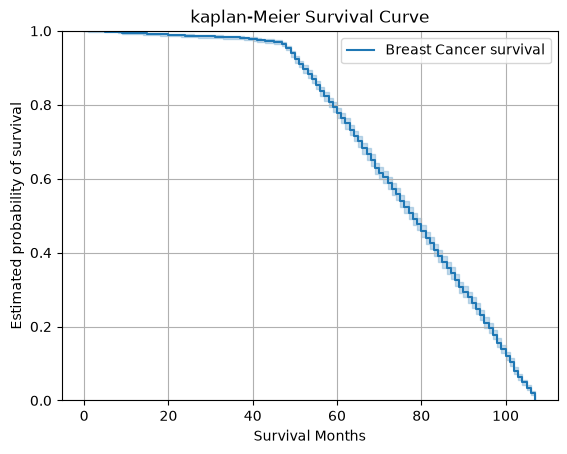

In [24]:
#Calculating the Kaplan-Meier curve in Python.

import pandas as pd
import pylab as pl
from lifelines import KaplanMeierFitter

#Prepare the data.
survival_data=data[["Survival Months","Event"]].dropna().copy()

kmf=KaplanMeierFitter()

kmf.fit(
    durations=survival_data["Survival Months"],
    event_observed=survival_data["Event"],
    label="Breast Cancer survival"
)

kmf.plot_survival_function()
pl.title("kaplan-Meier Survival Curve")
pl.xlabel("Survival Months")
pl.ylabel("Estimated probability of survival")
pl.ylim(0,1)
pl.grid()
pl.show()

In [30]:

print(kmf.predict([50,75,100]))

50     0.923002
75     0.540838
100    0.119693
Name: Breast Cancer survival, dtype: float64


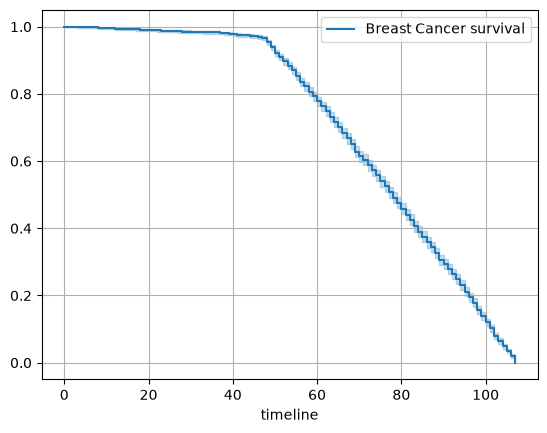

In [31]:
kmf.plot_survival_function()
pl.grid()
pl.show()


In [34]:
times=[50,75,100]
results=pd.DataFrame({
    "Time(Months)":times,
    "Survival Probability":kmf.predict(times).values})
results["Survival Percentage"]=(results["Survival Probability"] *100).round(2)
print(results)

   Time(Months)  Survival Probability  Survival Percentage
0            50              0.923002                92.30
1            75              0.540838                54.08
2           100              0.119693                11.97


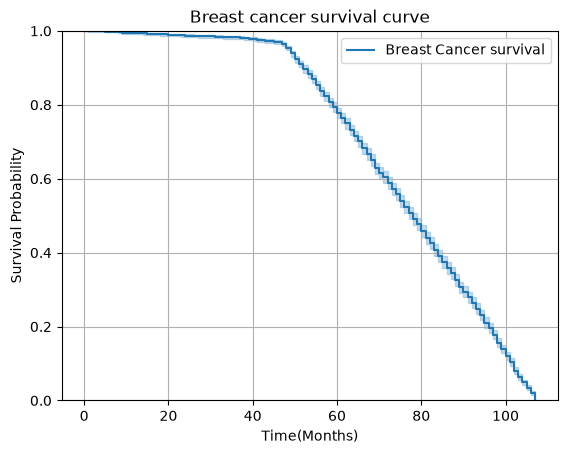

In [36]:
# Plotting Kaplan-meier survival curve

import pylab as pl

kmf.plot_survival_function()

pl.title("Breast cancer survival curve")
pl.xlabel("Time(Months)")
pl.ylabel("Survival Probability")
pl.ylim(0,1)
pl.grid(True)
pl.show()

In [4]:
# check the cancer stages.

print(data["6th Stage"].value_counts())

6th Stage
IIA     1305
IIB     1130
IIIA    1050
IIIC     472
IIIB      67
Name: count, dtype: int64


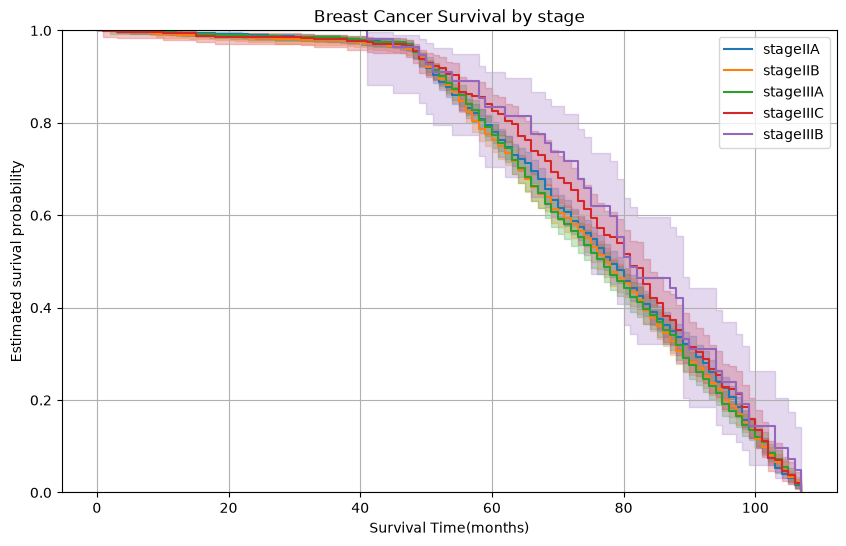

IIA 0.7803589970659885
IIB 0.763028253974313
IIIA 0.7730231774942677
IIIC 0.8253337771106729
IIIB 0.8342368924675759


In [7]:
import pylab as pl
from lifelines import KaplanMeierFitter

stages=["IIA","IIB","IIIA","IIIC","IIIB"]
pl.figure(figsize=(10,6))

for stage in stages:
    group=data[data["6th Stage"]==stage]

    kmf_stage=KaplanMeierFitter()

    kmf_stage.fit(
    durations=group["Survival Months"],
    event_observed=group["Event"],
    label=f"stage{stage}"
    )

    kmf_stage.plot_survival_function()

pl.title("Breast Cancer Survival by stage")
pl.xlabel("Survival Time(months)")
pl.ylabel("Estimated surival probability")
pl.ylim(0,1)
pl.grid()
pl.show()


## 📌Calculating the estimated Probability of surviving beyong 60 months (5years) at different stages.
from lifelines import KaplanMeierFitter

for stage in stages:
    group = data[data["6th Stage"] == stage]

    kmf_stage = KaplanMeierFitter()

    kmf_stage.fit(
        durations=group["Survival Months"],
        event_observed=group["Event"]
    )

    print(stage, kmf_stage.predict(60))

## ✅Logrank Test : Test whether the survival distribution of groups differ statistically.

In [16]:
from lifelines.statistics import multivariate_logrank_test

📌#multivariate_logrank_test: Used to compare multiple groups together.
logrank_results=multivariate_logrank_test(
    data["Survival Months"],
    data["6th Stage"],
    data["Event"]
)

print("Test Statistic:",logrank_results.test_statistic)
✔️#Test-statistics: Measures how far the measured differences in survival events are from what we would expect if the groups had the same survival distributions.

print("p_value:",logrank_results.p_value)  
✔️# p_value: 0.2708 ,therefore we fail reject the null hypothesis.

Test Statistic: 5.164038224804193
p_value: 0.2708764481088748


In [17]:
from lifelines.statistics import logrank_test   📌#logrank_test : compares two groups.
from itertools import combinations              📌#Import python tools that generate combinations.   
import pandas as pd
from statsmodels.stats.multitest import multipletests

stages = ["IIA", "IIB", "IIIA", "IIIB", "IIIC"]

test_data = data[
    ["Survival Months", "6th Stage", "Event"]
].dropna().copy()

results = []

for stage1, stage2 in combinations(stages, 2):

    group1 = test_data[test_data["6th Stage"] == stage1]
    group2 = test_data[test_data["6th Stage"] == stage2]

    test = logrank_test(
        group1["Survival Months"],
        group2["Survival Months"],
        event_observed_A=group1["Event"],
        event_observed_B=group2["Event"]
    )

    results.append({
        "Stage 1": stage1,
        "Stage 2": stage2,
        "Test Statistic": test.test_statistic,
        "P-value": test.p_value
    })

pairwise_results = pd.DataFrame(results)

pairwise_results["Adjusted P-value"] = multipletests(
    pairwise_results["P-value"],
    method="holm"
)[1]

print(pairwise_results)

#📌 None of the pairwise comparisons provides statistically  significant evidence  of a difference in a survival distributions between the 2 stages compared.

  Stage 1 Stage 2  Test Statistic   P-value  Adjusted P-value
0     IIA     IIB        0.183446  0.668428          1.000000
1     IIA    IIIA        0.242037  0.622739          1.000000
2     IIA    IIIB        1.968929  0.160562          0.983586
3     IIA    IIIC        1.874558  0.170954          0.983586
4     IIB    IIIA        0.001697  0.967139          1.000000
5     IIB    IIIB        2.205571  0.137513          0.983586
6     IIB    IIIC        2.713786  0.099485          0.983586
7    IIIA    IIIB        2.384528  0.122542          0.983586
8    IIIA    IIIC        2.731958  0.098359          0.983586
9    IIIB    IIIC        0.563975  0.452663          1.000000


# 📌 Cox Proportional Hazards Model : how different factors are associated with the risk of an event happening over time.

In [3]:
import pandas as pd
import numpy as np
from lifelines import CoxPHFitter

cox_data = data[
    [
        "Survival Months",
        "Event",
        "Age",
        "Tumor Size",
        "Regional Node Examined",
        "Reginol Node Positive",
        "6th Stage",
        "Estrogen Status",
        "Progesterone Status"
    ]
].copy()

print(cox_data.head())

print(cox_data.dtypes)

print(cox_data.isnull().sum())

   Survival Months  Event  Age  Tumor Size  Regional Node Examined  \
0               60      1   68           4                      24   
1               62      1   50          35                      14   
2               75      1   58          63                      14   
3               84      1   58          18                       2   
4               50      1   47          41                       3   

   Reginol Node Positive 6th Stage Estrogen Status Progesterone Status  
0                      1       IIA        Positive            Positive  
1                      5      IIIA        Positive            Positive  
2                      7      IIIC        Positive            Positive  
3                      1       IIA        Positive            Positive  
4                      1       IIB        Positive            Positive  
Survival Months            int64
Event                      int64
Age                        int64
Tumor Size                 int64
Regional 

In [4]:
cox_data = pd.get_dummies(
    cox_data,
    columns=[
        "6th Stage",
        "Estrogen Status",
        "Progesterone Status"
    ],
    drop_first=True,
    dtype=int
)

print(cox_data.head())
print(cox_data.columns.tolist())

   Survival Months  Event  Age  Tumor Size  Regional Node Examined  \
0               60      1   68           4                      24   
1               62      1   50          35                      14   
2               75      1   58          63                      14   
3               84      1   58          18                       2   
4               50      1   47          41                       3   

   Reginol Node Positive  6th Stage_IIB  6th Stage_IIIA  6th Stage_IIIB  \
0                      1              0               0               0   
1                      5              0               1               0   
2                      7              0               0               0   
3                      1              0               0               0   
4                      1              1               0               0   

   6th Stage_IIIC  Estrogen Status_Positive  Progesterone Status_Positive  
0               0                         1         

In [7]:
from lifelines import CoxPHFitter
cph = CoxPHFitter()
cph.fit(
    cox_data,
    duration_col="Survival Months",
    event_col="Event"
)
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 4024 total observations, 616 right-censored observations>
             duration col = 'Survival Months'
                event col = 'Event'
      baseline estimation = breslow
   number of observations = 4024
number of events observed = 3408
   partial log-likelihood = -24457.94
         time fit was run = 2026-11-05 14:46:17 UTC

---
                              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                     
Age                           0.00      1.00      0.00           -0.00            0.00                1.00                1.00
Tumor Size                    0.00      1.00      0.00           -0.00            0.00                1.00                1.00
Regional Node Examined        0.00      1.00      0.00           -0.00            0.01                1.00                1.01
Reginol Node Positive        -0.01      0.99      0.01           -0.02            0.01                0.98                1.01
6th Stage_IIB                 0.01      1.01      0.05           -0.08            0.10                0.92                1.10
6th Stage_IIIA                0.02      1.02      0.06           -0.10            0.15                0.91                1.16
6th Stage_IIIB               -0.21      0.81      0.16           -0.52            0.10                0.59                1.11
6th Stage_IIIC               -0.02      0.98      0.13           -0.26            0.23                0.77                1.26
Estrogen Status_Positive      0.10      1.11      0.09           -0.07            0.28                0.93                1.32
Progesterone Status_Positive  0.17      1.18      0.05            0.06            0.27                1.06                1.31

                              cmp to     z      p  -log2(p)
covariate                                                  
Age                             0.00  0.07   0.95      0.08
Tumor Size                      0.00  0.44   0.66      0.60
Regional Node Examined          0.00  1.01   0.31      1.69
Reginol Node Positive           0.00 -0.87   0.38      1.39
6th Stage_IIB                   0.00  0.16   0.88      0.19
6th Stage_IIIA                  0.00  0.38   0.71      0.50
6th Stage_IIIB                  0.00 -1.31   0.19      2.40
6th Stage_IIIC                  0.00 -0.13   0.90      0.15
Estrogen Status_Positive        0.00  1.14   0.26      1.97
Progesterone Status_Positive    0.00  3.06 <0.005      8.80
---
Concordance = 0.52
Partial AIC = 48935.88
log-likelihood ratio test = 24.50 on 10 df
-log2(p) of ll-ratio test = 7.29


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'Age' failed the non-proportional test: p-value is 0.0358.

   Advice 1: the functional form of the variable 'Age' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'Age' using pd.cut, and then specify it in `strata=['Age',
...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment..

[[<Axes: xlabel='rank-transformed time\n(p=0.0358)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0379)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.4735)'>,
  <Axes: xlabel='km-transformed time\n(p=0.4527)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.8757)'>,
  <Axes: xlabel='km-transformed time\n(p=0.9013)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.2248)'>,
  <Axes: xlabel='km-transformed time\n(p=0.2138)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1313)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1146)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1201)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1054)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.9162)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8828)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.6060)'>,
  <Axes: xlabel='km-transformed time\n(p=0.5733)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.6698)'>,
  <Axes: xlabel='km-transformed time\n(p=0.6694)'>],
 [<Axes: xlabel='rank-transformed tim

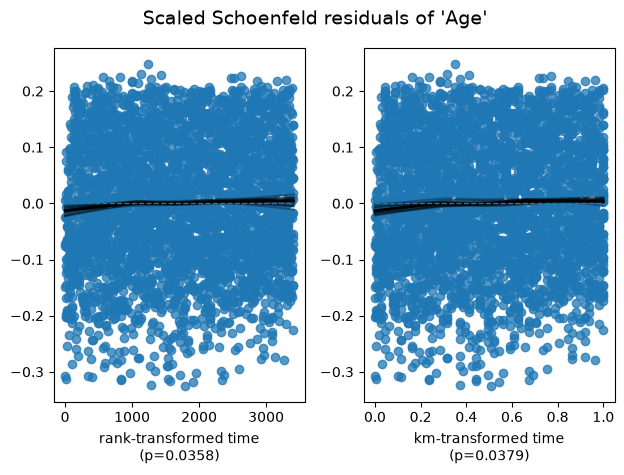

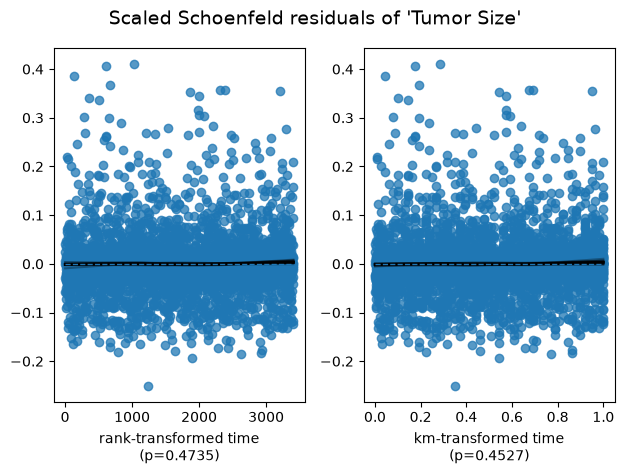

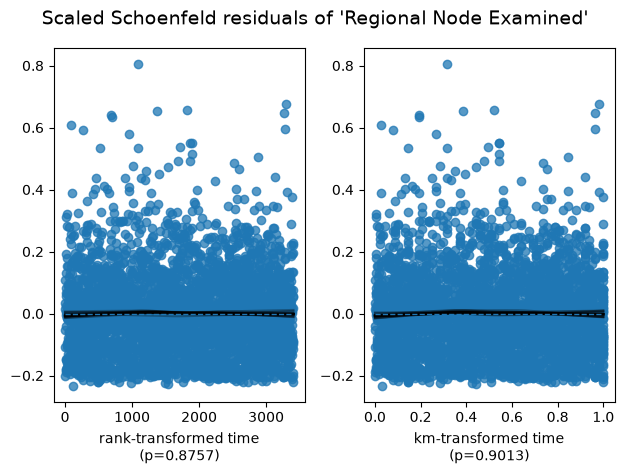

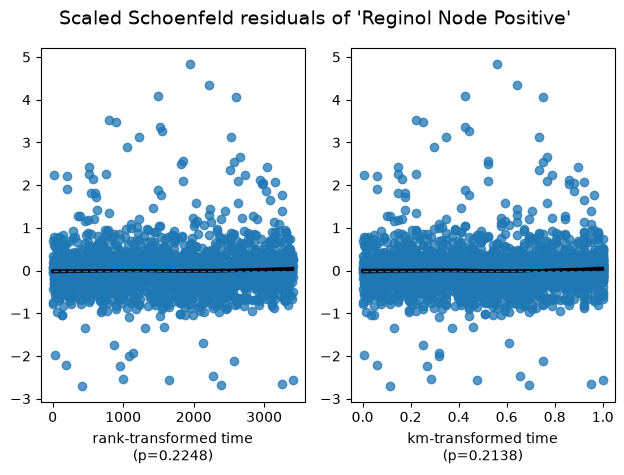

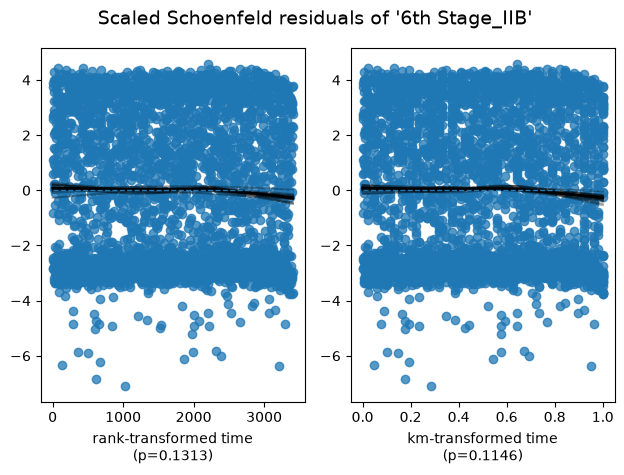

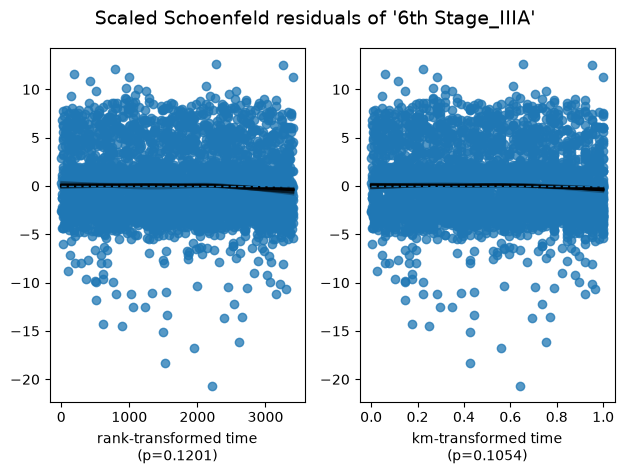

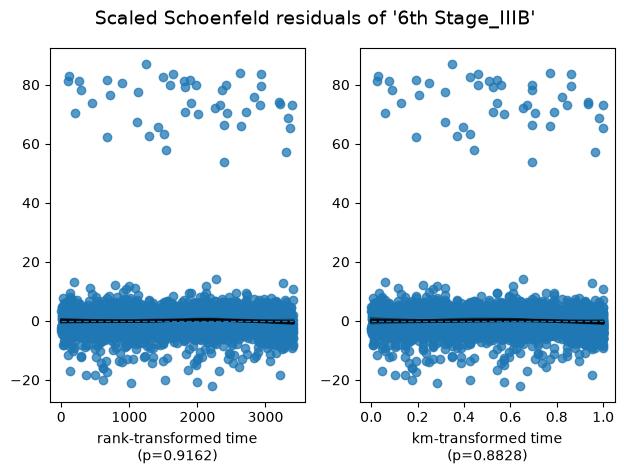

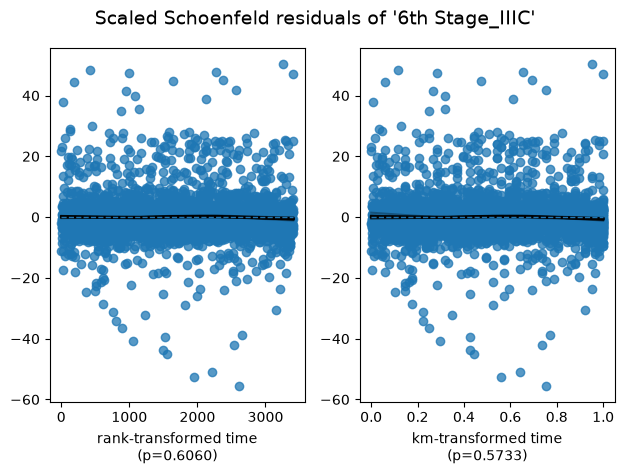

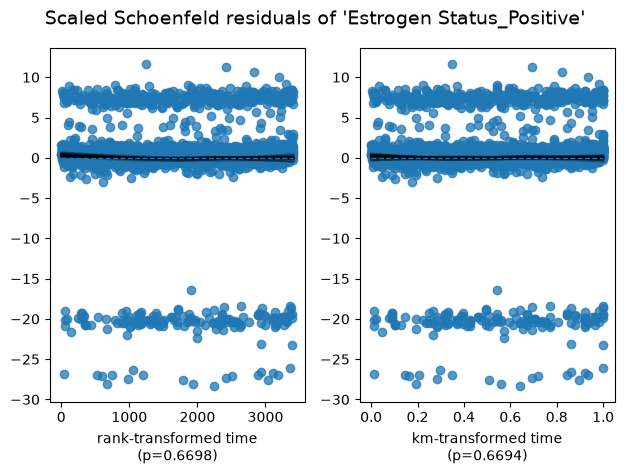

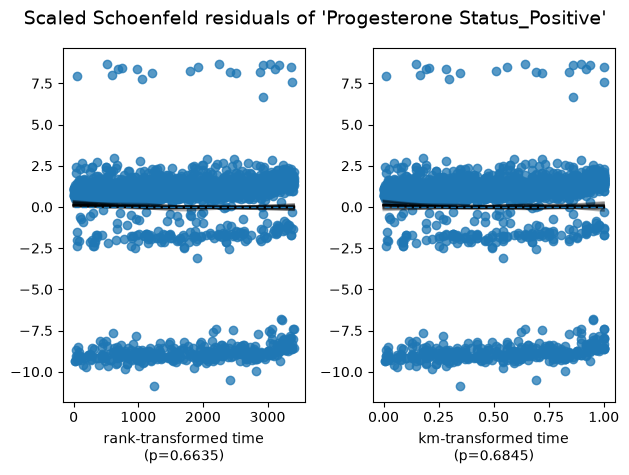

In [8]:
cph.check_assumptions(
    cox_data,
    p_value_threshold=0.05,
    show_plots=True
)

In [11]:
patient = cox_data.drop(
    columns=["Survival Months", "Event"]
).iloc[[0]]
survival_prediction = cph.predict_survival_function(patient)

print(survival_prediction)

              0
1.0    0.999736
2.0    0.999472
3.0    0.998943
4.0    0.998679
5.0    0.998149
...         ...
103.0  0.061861
104.0  0.047914
105.0  0.034922
106.0  0.021874
107.0  0.007417

[107 rows x 1 columns]


In [15]:
times = [12, 36, 60]

predictions = cph.predict_survival_function(
    patient,
    times=times
)

print(predictions)
print(patient)
print(patient.shape)
print(cph)


             0
12.0  0.993624
36.0  0.981943
60.0  0.769073
   Age  Tumor Size  Regional Node Examined  Reginol Node Positive  \
0   68           4                      24                      1   

   6th Stage_IIB  6th Stage_IIIA  6th Stage_IIIB  6th Stage_IIIC  \
0              0               0               0               0   

   Estrogen Status_Positive  Progesterone Status_Positive  
0                         1                             1  
(1, 10)
<lifelines.CoxPHFitter: fitted with 4024 total observations, 616 right-censored observations>


# 📌Prepare dataset for powerBI📈

In [16]:
powerbi_data = data.copy()

powerbi_data.to_csv(
    "breast_cancer_survival_analysis.csv",
    index=False
)